**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 2**
Pandas para el análisis de datos en Python

---

*   NOMBRE: Oliver Ulises Fajardo Calderón
*   MATRÍCULA: A01610928


---

En esta actividad trabajarás con el archivo `cleaned_weather.csv`, un extracto del conjunto de datos meteorológicos a lo largo de todo el año 2020 en una estación del Instituto *Max Planck* (Alemania) disponible en Kaggle.

Los datos meteorológicos fueron registrados cada 10 minutos e incluyen los siguientes indicadores:

*   `timestamp`: Fecha y hora de la observación.
*   `p`: Presión atmosférica en milibares (mbar)
*   `T`: Temperatura del aire en grados Celsius (°C)
*   `Tpot`: Temperatura potencial en Kelvin (K)
*   `rh`: Humedad relativa en porcentaje (%)
*   `VPact`: Presión real de vapor en milibares (mbar)
*   `sh`: Humedad específica en gramos por kilogramo (g/kg)
*   `H2OC`: Concentración de vapor de agua en milimoles por mol (mmol/mol) de aire seco
*   `rho`: Densidad del aire en gramos por metro cúbico (g/m³)
*   `wv`: Velocidad del viento en metros por segundo (m/s)
*   `wd`: Dirección del viento en grados (°)
*   `rain`: Precipitación total en milímetros (mm)
*   `raining`: Duración de la lluvia en segundos (s)

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.


In [1]:
# Importa las librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt


1.	Descarga el archivo: `cleaned_weather.csv` y guarda, en un dataframe (`weather_df`), todos sus registros.
- Determina la dimensionalidad del dataframe y obtén los identificadores de columnas.
- Renombra las columnas para facilitar la interpretación de los indicadores en los ejercicios siguientes:
  - `medicion, presion_atmosferica, temperatura_celsius, temperatura_kelvin, humedad_relativa, presion_vapor, humedad_especifica, concentracion_vapor, densidad_aire, velocidad_viento, direccion_viento, precipitacion_total, duracion_lluvia`
- Muestra los primeros y los últimos 5 registros.
- ¿Hay valores faltantes en el dataframe?





In [2]:
weather_df = pd.read_csv("cleaned_weather.csv")

print("Dimensionalidad:", weather_df.shape)
print("Columnas originales:", weather_df.columns.tolist())

weather_df.columns = [
    "medicion", "presion_atmosferica", "temperatura_celsius",
    "temperatura_kelvin", "humedad_relativa", "presion_vapor",
    "humedad_especifica", "concentracion_vapor", "densidad_aire",
    "velocidad_viento", "direccion_viento", "precipitacion_total",
    "duracion_lluvia"
]

print("\nPrimeros 5 registros:")
display(weather_df.head())

print("\nÚltimos 5 registros:")
display(weather_df.tail())

print("\nValores faltantes por columna:")
display(weather_df.isna().sum())


Dimensionalidad: (52696, 13)
Columnas originales: ['timestamp', 'p', 'T', 'Tpot', 'rh', 'VPact', 'sh', 'H2OC', 'rho', 'wv', 'wd', 'rain', 'raining']

Primeros 5 registros:


,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
0,01/01/20 0:10,1008.89,0.71,273.18,86.1,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0
1,01/01/20 0:20,1008.76,0.75,273.22,85.2,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0
2,01/01/20 0:30,1008.66,0.73,273.21,85.1,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0
3,01/01/20 0:40,1008.64,0.37,272.86,86.3,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0
4,01/01/20 0:50,1008.61,0.33,272.82,87.4,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0



Últimos 5 registros:


,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
52691,31/12/20 23:20,978.32,2.28,277.16,80.0,5.76,3.67,5.89,1234.61,0.73,180.6,0.0,0
52692,31/12/20 23:30,978.30,2.13,277.01,83.1,5.92,3.77,6.05,1235.20,0.43,174.0,0.0,0
52693,31/12/20 23:40,978.26,1.99,276.88,82.2,5.80,3.69,5.93,1235.82,0.38,248.9,0.0,0
52694,31/12/20 23:50,978.26,2.07,276.95,81.4,5.77,3.68,5.90,1235.49,0.57,196.6,0.0,0
52695,01/01/21 0:00,978.24,2.01,276.89,82.4,5.82,3.71,5.95,1235.71,0.57,221.3,0.0,0



Valores faltantes por columna:


medicion               0
presion_atmosferica    0
temperatura_celsius    0
temperatura_kelvin     0
humedad_relativa       0
presion_vapor          0
humedad_especifica     0
concentracion_vapor    0
densidad_aire          0
velocidad_viento       0
direccion_viento       0
precipitacion_total    0
duracion_lluvia        0
dtype: int64

**Respuesta / análisis:** El dataframe contiene 52,696 filas y 13 columnas. No se detectan valores faltantes (`NaN`) en ninguna de las columnas.

2. Determina el tipo de datos que tienen las columnas.
- Cambia la columna `medicion` a datetime utilizando el formato: `%d/%m/%y %H:%M`
- Obtén dos columnas adicionales separando `medicion` en `fecha` y `hora`

In [3]:
print("Tipos de datos originales:")
display(weather_df.dtypes)

weather_df["medicion"] = pd.to_datetime(
    weather_df["medicion"],
    format="%d/%m/%y %H:%M"
)

weather_df["fecha"] = weather_df["medicion"].dt.date
weather_df["hora"] = weather_df["medicion"].dt.time

print("\nTipos de datos después de la transformación:")
display(weather_df.dtypes)


Tipos de datos originales:


medicion                object
presion_atmosferica    float64
temperatura_celsius    float64
temperatura_kelvin     float64
humedad_relativa       float64
presion_vapor          float64
humedad_especifica     float64
concentracion_vapor    float64
densidad_aire          float64
velocidad_viento       float64
direccion_viento       float64
precipitacion_total    float64
duracion_lluvia          int64
dtype: object


Tipos de datos después de la transformación:


medicion               datetime64[ns]
presion_atmosferica           float64
temperatura_celsius           float64
temperatura_kelvin            float64
humedad_relativa              float64
presion_vapor                 float64
humedad_especifica            float64
concentracion_vapor           float64
densidad_aire                 float64
velocidad_viento              float64
direccion_viento              float64
precipitacion_total           float64
duracion_lluvia                 int64
fecha                          object
hora                           object
dtype: object

**Respuesta / análisis:** La columna `medicion` se convirtió a tipo `datetime64[ns]`. A partir de ella se generaron las columnas `fecha` y `hora`, lo que permite analizar por día y por intervalo horario.

3. Determina la cantidad de valores únicos de cada columna.
- La columna `medicion` tiene un valor menos que el número total de filas del dataframe, lo que indica que hay una fecha duplicada. Identifica cuál es.
- Comprueba si las demás columnas también contienen los mismos valores; si es así, elimina  uno de los registros duplicados.


In [4]:
print("Valores únicos por columna:")
display(weather_df.nunique())

duplicados_medicion = weather_df[
    weather_df.duplicated(subset="medicion", keep=False)
]

print("\nRegistros con medición duplicada:")
display(duplicados_medicion)

print(
    "\n¿Los dos registros duplicados son idénticos en todas sus columnas?:",
    duplicados_medicion.nunique().max() == 1
)

weather_df = weather_df.drop_duplicates().reset_index(drop=True)
print("\nDimensionalidad después de eliminar el duplicado:", weather_df.shape)


Valores únicos por columna:


medicion               52695
presion_atmosferica     5052
temperatura_celsius     3680
temperatura_kelvin      3836
humedad_relativa        5494
presion_vapor           2059
humedad_especifica      1337
concentracion_vapor     2087
densidad_aire          14826
velocidad_viento         977
direccion_viento        8099
precipitacion_total       42
duracion_lluvia           61
fecha                    367
hora                     144
dtype: int64


Registros con medición duplicada:


,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
19043,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00
19044,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00



¿Los dos registros duplicados son idénticos en todas sus columnas?: True



Dimensionalidad después de eliminar el duplicado: (52695, 15)


**Respuesta / análisis:** La medición duplicada corresponde al **12 de mayo de 2020 a las 06:00**. Los dos registros contienen los mismos valores en todas las columnas, por lo que se elimina uno de ellos.

4. Imprime nuevamente las cantidad de valores únicos por columna.
- ¿Por qué son 144 horas diferentes?
- La cantidad de combinaciones únicas de fecha y hora no coincide con el número total de mediciones. Aunque no haya valores NaN, esto no garantiza que no se hayan omitido registros. Identifica las fechas en las que faltan mediciones.
- Una vez concluido el análisis de mediciones faltantes, elimina todos los registros que no correspondan al año 2020 y la columna `medicion`.


In [5]:
print("Valores únicos después de eliminar el duplicado:")
display(weather_df.nunique())

conteo_por_fecha = weather_df.groupby("fecha").size()

fechas_incompletas_2020 = conteo_por_fecha[
    (pd.to_datetime(conteo_por_fecha.index).year == 2020) &
    (conteo_por_fecha < 144)
]

print("\nFechas de 2020 con menos de 144 mediciones:")
display(fechas_incompletas_2020.to_frame("numero_mediciones"))

weather_df = weather_df[
    pd.to_datetime(weather_df["fecha"]).dt.year == 2020
].copy()

weather_df = weather_df.drop(columns="medicion")

print("\nDimensionalidad final para 2020:", weather_df.shape)


Valores únicos después de eliminar el duplicado:


medicion               52695
presion_atmosferica     5052
temperatura_celsius     3680
temperatura_kelvin      3836
humedad_relativa        5494
presion_vapor           2059
humedad_especifica      1337
concentracion_vapor     2087
densidad_aire          14826
velocidad_viento         977
direccion_viento        8099
precipitacion_total       42
duracion_lluvia           61
fecha                    367
hora                     144
dtype: int64


Fechas de 2020 con menos de 144 mediciones:


,numero_mediciones
fecha,
2020-01-01,143
2020-05-29,135



Dimensionalidad final para 2020: (52694, 14)


**Respuesta / análisis:** Hay **144 horas/intervalos distintos** porque las mediciones se realizan cada 10 minutos: 24 horas × 6 mediciones por hora = 144 intervalos posibles en un día. En 2020 hay dos fechas incompletas: **1 de enero de 2020 (143 mediciones)** y **29 de mayo de 2020 (135 mediciones)**. Después se eliminan los registros ajenos a 2020 y la columna `medicion`.

5. Obtén un dataframe `indicadores_diarios` que sólo almacene el mayor valor de las mediciones por fecha para responder:
- ¿Cuál fue la máxima precipitación y a qué fecha pertenece?
- ¿Cuáles fueron los tres días con las velocidades de viento más altas registradas?
- ¿Cuántos días rebasaron el 90% de humedad relativa y los 30° celsius?

In [6]:
indicadores_diarios = weather_df.groupby("fecha").max(numeric_only=True)

max_precipitacion = indicadores_diarios["precipitacion_total"].max()
fecha_max_precipitacion = indicadores_diarios["precipitacion_total"].idxmax()

top_3_viento = indicadores_diarios["velocidad_viento"].nlargest(3)

dias_humedad_temperatura = indicadores_diarios[
    (indicadores_diarios["humedad_relativa"] > 90) &
    (indicadores_diarios["temperatura_celsius"] > 30)
]

print(
    f"Máxima precipitación: {max_precipitacion} mm, "
    f"fecha: {fecha_max_precipitacion}"
)

print("\nTres días con mayor velocidad de viento:")
display(top_3_viento.to_frame("velocidad_viento"))

print(
    "\nDías que rebasaron 90% de humedad relativa y 30 °C:",
    len(dias_humedad_temperatura)
)


Máxima precipitación: 11.2 mm, fecha: 2020-06-16

Tres días con mayor velocidad de viento:


,velocidad_viento
fecha,
2020-02-10,13.77
2020-02-16,13.00
2020-02-09,12.52



Días que rebasaron 90% de humedad relativa y 30 °C: 5


**Respuesta / análisis:** La precipitación máxima diaria fue de **11.2 mm el 16 de junio de 2020**. Los tres días con velocidades máximas de viento más altas fueron **10 de febrero (13.77 m/s), 16 de febrero (13.00 m/s) y 9 de febrero (12.52 m/s)**. Hubo **5 días** cuyos máximos diarios rebasaron tanto 90% de humedad relativa como 30 °C.

6. La función `describe()` resume múltiples estadísticas descriptivas. Utiliza esta función para explorar y responder las preguntas sobre las variables en el dataframe de `indicadores_diarios `:
- ¿Cuál es la desviación estándar de la concentración de vapor y qué indica?
- ¿Cuál es la mediana de la presión atmosférica y qué significa?
- ¿Cuál es el tercer cuartil de la duración de la lluvia y cómo se interpreta?

In [7]:
estadisticas = indicadores_diarios.describe()
display(estadisticas)

desv_concentracion = estadisticas.loc["std", "concentracion_vapor"]
mediana_presion = estadisticas.loc["50%", "presion_atmosferica"]
q3_lluvia = estadisticas.loc["75%", "duracion_lluvia"]

print(f"Desviación estándar de concentración de vapor: {desv_concentracion:.2f}")
print(f"Mediana de presión atmosférica: {mediana_presion:.2f} mbar")
print(f"Tercer cuartil de duración de lluvia: {q3_lluvia:.2f} s")


,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,992.977842,15.343770,289.431667,90.886530,11.409454,7.214016,11.539180,1232.622814,5.245164,317.673689,0.314208,240.382514
std,8.543447,7.850339,7.942175,9.201588,4.507555,2.872647,4.573267,32.702446,2.097012,50.611324,0.979721,273.840002
min,959.900000,-0.120000,273.460000,55.440000,3.320000,2.050000,3.290000,1167.050000,1.570000,69.570000,0.000000,0.000000
25%,988.015000,8.840000,282.732500,85.400000,7.647500,4.832500,7.742500,1207.590000,3.662500,279.075000,0.000000,0.000000
50%,993.300000,15.060000,289.160000,93.250000,10.715000,6.705000,10.735000,1231.455000,4.880000,346.650000,0.000000,0.000000
75%,998.432500,21.695000,295.957500,99.900000,14.462500,9.180000,14.685000,1256.057500,6.495000,357.300000,0.200000,600.000000
max,1020.070000,34.800000,309.130000,100.000000,24.160000,15.400000,24.530000,1318.520000,13.770000,360.000000,11.200000,600.000000


Desviación estándar de concentración de vapor: 4.57
Mediana de presión atmosférica: 993.30 mbar
Tercer cuartil de duración de lluvia: 600.00 s


**Respuesta / análisis:** La desviación estándar de la concentración de vapor es aproximadamente **4.57 mmol/mol**; indica cuánto se dispersan los máximos diarios respecto de su media. La mediana de la presión atmosférica es **993.30 mbar**, lo que significa que la mitad de los máximos diarios está por debajo de ese valor y la otra mitad por encima. El tercer cuartil de la duración de lluvia es **600 s**; esto indica que 75% de los máximos diarios de duración de lluvia son de 600 segundos o menos.

7.	Dibuja un histograma para cada una de las columnas de `indicadores_diarios`.

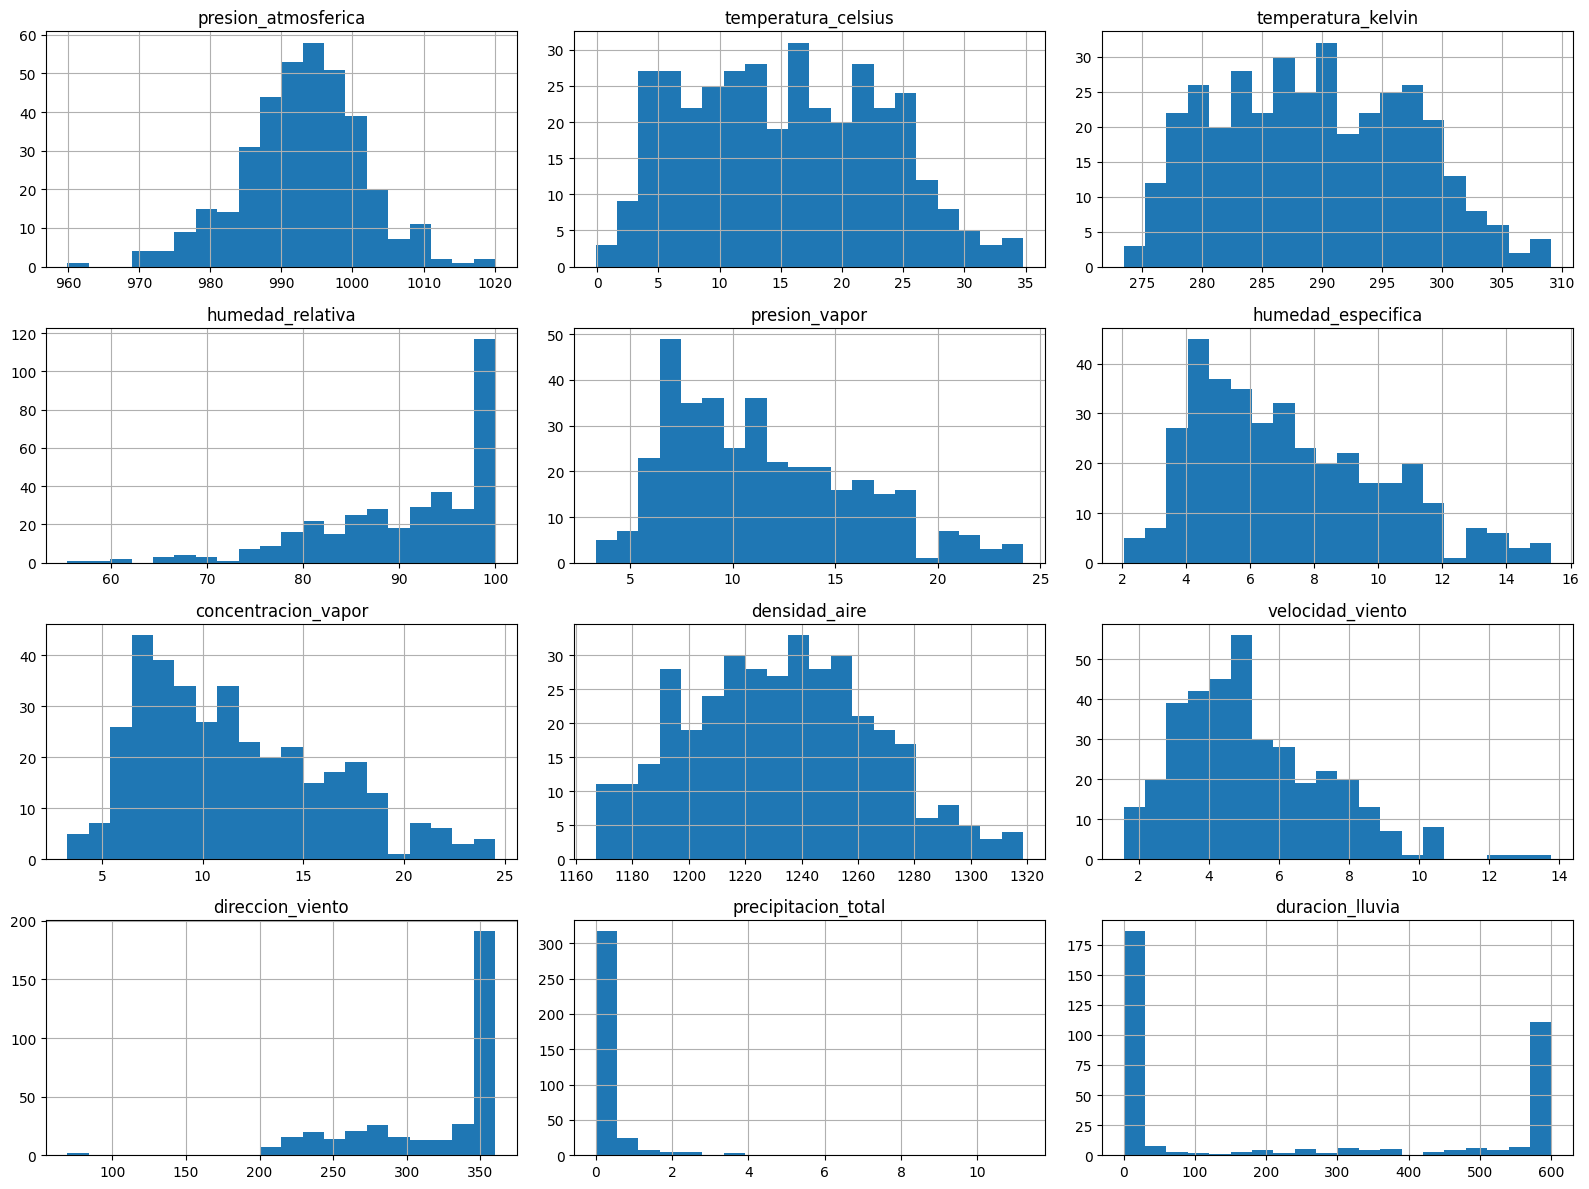

In [8]:
indicadores_diarios.hist(figsize=(16, 12), bins=20)
plt.tight_layout()
plt.show()


8. Utiliza el dataframe de indicadores diarios para crear un nuevo dataframe `indicadores_mensuales`. Para ello:
- Crea una nueva columna `mes` a partir de la fecha que se encuentra en el índice.
- Haciendo uso de `groupby()`, calcula los promedios mensuales y conserva únicamente las columnas `humedad_relativa`, `temperatura_celsius` y `velocidad_viento` en el nuevo dataframe.

In [9]:
indicadores_diarios["mes"] = pd.to_datetime(
    indicadores_diarios.index
).month

columnas_mensuales = [
    "humedad_relativa",
    "temperatura_celsius",
    "velocidad_viento"
]

indicadores_mensuales = (
    indicadores_diarios
    .groupby("mes")[columnas_mensuales]
    .mean()
)

display(indicadores_mensuales)


,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


9. Construye el mismo dataframe mensual, pero esta vez utilizando la función `pivot_table()`.
- Añade la columna `indice_calor` usando la fórmula de Thom (*Temperature - Humidity Index*, TDI):
> `temperatura_celsius + 0.33 x humedad_relativa - 0.7 x velocidad_viento - 4`

In [10]:
indicadores_mensuales_pivot = indicadores_diarios.pivot_table(
    index="mes",
    values=columnas_mensuales,
    aggfunc="mean"
)[columnas_mensuales]

indicadores_mensuales_pivot["indice_calor"] = (
    indicadores_mensuales_pivot["temperatura_celsius"]
    + 0.33 * indicadores_mensuales_pivot["humedad_relativa"]
    - 0.7 * indicadores_mensuales_pivot["velocidad_viento"]
    - 4
)

display(indicadores_mensuales_pivot)


,humedad_relativa,temperatura_celsius,velocidad_viento,indice_calor
mes,,,,
1,89.776129,6.821290,5.031935,28.925058
2,85.719655,8.962414,7.489655,28.007141
3,85.372903,9.683871,6.421290,29.362026
4,80.938667,16.879667,4.997000,36.091527
5,87.464839,17.135484,4.865806,38.592816
6,94.256000,22.212000,5.296667,45.608813
7,85.959355,24.336129,4.830323,45.321490
8,92.002581,26.097742,5.040323,48.930368
9,97.570000,21.571667,4.153333,46.862433


10. Recuerda que de las cuatro funciones estudiadas para manipular la estructura del dataframe:
- `melt/pivot` hacen las transformaciones de manera controlada, es decir puedes
definir por medio de sus parámetros qué variables quedarán como índices, columnas y valores.
- `stack/unstack` la conversión se aplica siempre sobre los niveles inferiores de index/columns.
- Convierte el dataframe del ejercicio anterior a formato largo usando: `melt()` y `stack()` y comenta las diferencias.

In [11]:
# Formato largo con melt()
formato_largo_melt = (
    indicadores_mensuales_pivot
    .reset_index()
    .melt(
        id_vars="mes",
        var_name="indicador",
        value_name="valor"
    )
)

print("Formato largo con melt():")
display(formato_largo_melt)

# Formato largo con stack()
formato_largo_stack = (
    indicadores_mensuales_pivot
    .stack(future_stack=True)
    .rename("valor")
    .reset_index()
    .rename(columns={"level_1": "indicador"})
)

print("\nFormato largo con stack():")
display(formato_largo_stack)


Formato largo con melt():


,mes,indicador,valor
0,1,humedad_relativa,89.776129
1,2,humedad_relativa,85.719655
2,3,humedad_relativa,85.372903
3,4,humedad_relativa,80.938667
4,5,humedad_relativa,87.464839
5,6,humedad_relativa,94.256000
6,7,humedad_relativa,85.959355
7,8,humedad_relativa,92.002581
8,9,humedad_relativa,97.570000
9,10,humedad_relativa,96.950645



Formato largo con stack():


,mes,indicador,valor
0,1,humedad_relativa,89.776129
1,1,temperatura_celsius,6.821290
2,1,velocidad_viento,5.031935
3,1,indice_calor,28.925058
4,2,humedad_relativa,85.719655
5,2,temperatura_celsius,8.962414
6,2,velocidad_viento,7.489655
7,2,indice_calor,28.007141
8,3,humedad_relativa,85.372903
9,3,temperatura_celsius,9.683871


**Comentario sobre `melt()` y `stack()`:** Ambos métodos permiten pasar los datos de formato ancho a formato largo. `melt()` permite elegir explícitamente qué columnas permanecen como identificadores y cuáles se convierten en pares variable-valor. `stack()` reorganiza los niveles de columnas hacia el índice; es especialmente útil cuando la estructura ya está definida por índices y columnas. En este ejercicio ambos producen una representación equivalente de los indicadores mensuales en formato largo.

---

**Declaración de uso de IA**

OpenAI. (2026). *ChatGPT (GPT-5.6 Sol)* [Modelo de lenguaje grande], utilizado como apoyo para generación de código, depuración y optimización de la solución.

La revisión, ejecución y responsabilidad final del contenido presentado corresponden al autor.

---